# Rozdział 17: Przetwarzanie sygnałów (Signal Processing)

W tym notatniku przyglądamy się metodom numerycznego przetwarzania sygnałów w Pythonie na podstawie 17. rozdziału książki *Numerical Python* Roberta Johanssona. Sygnałem może być dowolna wielkość zmieniająca się w czasie (sygnał czasowy, np. dźwięk lub temperatura) albo w przestrzeni (sygnał przestrzenny, np. obraz 2D). Choć w rzeczywistości większość sygnałów ma charakter ciągły, w obliczeniach komputerowych operujemy na sygnałach dyskretnych, powstałych przez próbkowanie sygnału ciągłego w równych odstępach czasu.

### Importowanie bibliotek
Na początek ładujemy niezbędne narzędzia z ekosystemu naukowego Pythona:
* **`scipy.fftpack`** – moduł dostarczający wydajne algorytmy szybkiej transformacji Fouriera (FFT) do analizy widmowej.
* **`scipy.signal`** – narzędzia do przetwarzania sygnałów: funkcje okien, sploty oraz projektowanie i aplikowanie filtrów cyfrowych (FIR, IIR).
* **`scipy.io.wavfile` / `scipy.io`** – moduły pozwalające na wczytywanie i zapisywanie plików audio w formacie WAV jako tablic NumPy.
* **`numpy`, `pandas`, `matplotlib`** – podstawowy zestaw do operacji tablicowych, obsługi szeregów czasowych i wizualizacji wyników.

In [3]:
from scipy import fftpack
from scipy import signal
import scipy.io.wavfile
from scipy import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

## 1. Analiza widmowa (Spectral Analysis) i Transformacja Fouriera

Analiza widmowa to jedno z najważniejszych zastosowań **transformacji Fouriera** – przekształcenia całkowego, które pozwala przenieść sygnał z **dziedziny czasu** $f(t)$ do **dziedziny częstotliwości** $F(\nu)$:
$$F(\nu) = \int_{-\infty}^{\infty} f(t) e^{-2\pi i \nu t} dt, \qquad f(t) = \int_{-\infty}^{\infty} F(\nu) e^{2\pi i \nu t} d\nu$$
Reprezentacja częstotliwościowa $F(\nu)$ (widmo amplitudowe, z którego można też wyznaczyć widmo mocy $|F(\nu)|^2$) ogromnie ułatwia wyodrębnianie dominujących częstotliwości ukrytych w sygnale, odszumianie czy rozwiązywanie równań różniczkowych.

**Przykład wprowadzający:** Symulowany sygnał z czystymi składowymi sinusoidalnymi o częstotliwościach $1\text{ Hz}$ oraz $22\text{ Hz}$ nałożonymi na losowy szum gaussowski.

### Generowanie zaszumionego sygnału w dziedzinie czasu
Tworzymy funkcję `signal_samples(t)`, która symuluje pomiar sygnału złożonego z dwóch czystych fal sinusoidalnych o znanych częstotliwościach i amplitudach:
* składowej o częstotliwości $1\text{ Hz}$ i amplitudzie $2$,
* składowej o częstotliwości $22\text{ Hz}$ i amplitudzie $3$,
* oraz nałożonego na nie szumu losowego o rozkładzie normalnym (gaussowskim) ze średnią $0$ i odchyleniem standardowym $2$ (`2 * np.random.randn(...)`).

**Po co to robimy?** W praktyce pomiary fizyczne niemal nigdy nie są idealnie czyste. Chcemy sprawdzić, jak za pomocą transformacji Fouriera wydobyć ukryte składowe harmoniczne z sygnału, który na pierwszy rzut oka wygląda jak chaotyczny szum.

In [4]:
def signal_samples(t):
    return (2 * np.sin(2 * np.pi * t) + 3 * np.sin(22 * 2 * np.pi * t) + 2 * np.random.randn(*np.shape(t)))

### Dobór parametrów próbkowania i twierdzenie Nyquista-Shannona
Aby móc badać sygnał ciągły metodami cyfrowymi, musimy zamienić go na ciąg próbek. Kluczową rolę odgrywa tu **twierdzenie o próbkowaniu (Nyquista-Shannona)**: sygnał ciągły o paśmie ograniczonym do maksymalnej częstotliwości $B$ (ang. *bandwidth*) można wiernie odtworzyć z próbek dyskretnych, jeśli częstotliwość próbkowania $f_s$ spełnia warunek:
$$f_s \ge 2B$$
Wartość $f_s / 2 = B$ nazywamy **częstotliwością Nyquista**.

W kodzie poniżej:
1. Zakładamy, że chcemy badać widmo częstotliwości aż do $B = 30\text{ Hz}$.
2. Zgodnie z twierdzeniem Nyquista ustalamy częstotliwość próbkowania na $f_s = 2B = 60\text{ Hz}$.
3. Określamy pożądaną rozdzielczość częstotliwościową $\Delta f = 0.01\text{ Hz}$ (odstęp między kolejnymi prążkami w widmie).
4. Wyliczamy minimalną liczbę próbek $N = f_s / \Delta f = 6000$, jaka jest potrzebna do uzyskania takiej rozdzielczości.

In [5]:
B = 30.0
f_s = 2 * B
delta_f = 0.01
N = int(f_s / delta_f); N

6000

### Całkowity czas pomiaru (okres próbkowania)
Rozdzielczość w dziedzinie częstotliwości $\Delta f$ jest bezpośrednio powiązana z całkowitym czasem rejestracji sygnału $T$ zależnością $\Delta f = 1 / T$. 
Znając liczbę próbek $N = 6000$ oraz częstotliwość próbkowania $f_s = 60\text{ Hz}$, obliczamy całkowity czas trwania pomiaru:
$$T = \frac{N}{f_s} = 100\text{ s}$$
Wniosek praktyczny: jeśli chcemy mieć bardzo dokładne (gęste) widmo częstotliwości, musimy zbierać próbki przez odpowiednio długi czas.

In [6]:
T = N / f_s; T

100.0

### Próbkowanie sygnału
Generujemy wektor czasu `t` zawierający $N = 6000$ równomiernie rozłożonych punktów w przedziale $[0, T]$ i obliczamy dla nich wartości badanego sygnału `f_t`.

In [7]:
t = np.linspace(0, T, N)
f_t = signal_samples(t)

### Wizualizacja sygnału w dziedzinie czasu
Rysujemy wygenerowany sygnał w pełnym oknie $100\text{ s}$ (po lewej) oraz w dużym powiększeniu dla pierwszych $5\text{ s}$ (po prawej). 
Jak widać na wykresach, losowy szum w dziedzinie czasu bardzo mocno maskuje czyste składowe sinusoidalne ($1\text{ Hz}$ i $22\text{ Hz}$) – patrząc na sam przebieg czasowy, trudno jednoznacznie ocenić, jakie częstotliwości tworzą nasz sygnał.

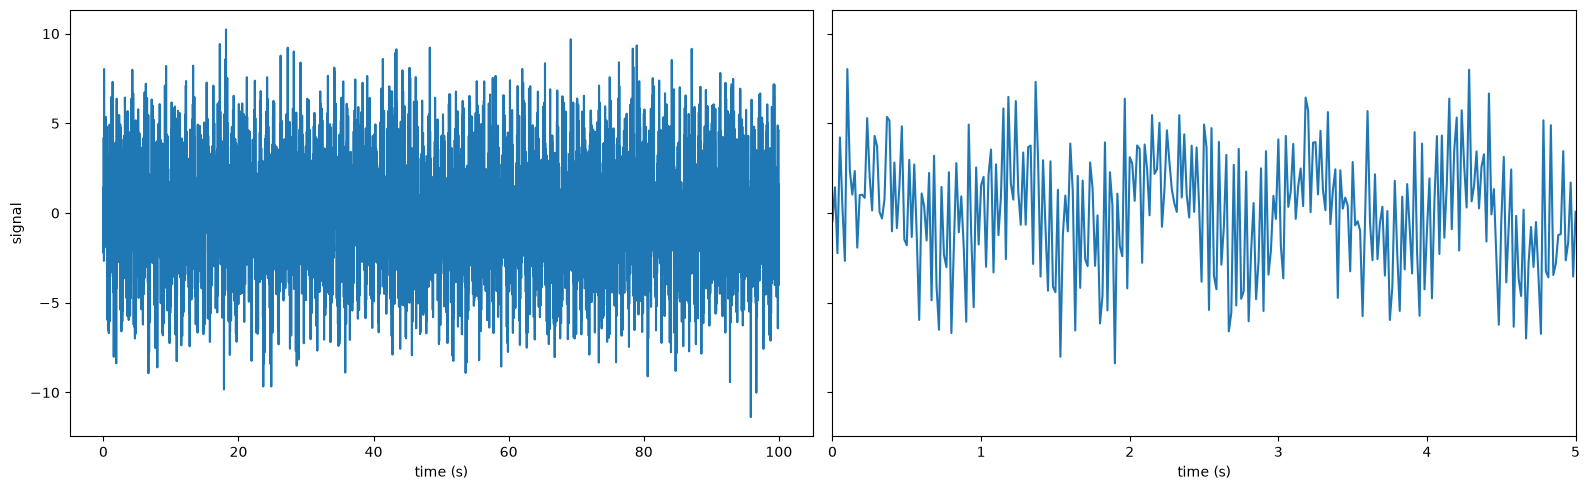

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
axes[0].plot(t, f_t)
axes[0].set_xlabel("time (s)")
axes[0].set_ylabel("signal")
axes[1].plot(t, f_t)
axes[1].set_xlim(0, 5)
axes[1].set_xlabel("time (s)")

plt.tight_layout()

### Obliczanie Dyskretnej Transformacji Fouriera (algorytm FFT)
Przechodzimy z dziedziny czasu do dziedziny częstotliwości. Dla ciągu $N$ próbek $(x_0, x_1, \dots, x_{N-1})$ **Dyskretna Transformacja Fouriera (DFT)** wyraża się wzorem:
$$X_k = \sum_{n=0}^{N-1} x_n e^{-i 2\pi k n / N}$$
Funkcja `fftpack.fft(f_t)` oblicza te wartości za pomocą algorytmu **Szybkiej Transformacji Fouriera (FFT)** w czasie $O(N \log N)$. Wynikiem jest tablica `F` zawierająca zespolone amplitudy odpowiadające kolejnym przedziałom (tzw. *binom*) częstotliwości.

In [12]:
 F = fftpack.fft(f_t); F

array([-112.30064102  -0.j        ,   75.59434473 -60.35207181j,
         24.85082681+135.62167883j, ...,  167.88675689+155.8588782j ,
         24.85082681-135.62167883j,   75.59434473 +60.35207181j],
      shape=(6000,))

### Wyznaczanie osi częstotliwości
Sama tablica `F` zwracana przez `fft` zawiera jedynie amplitudy, ale nie mówi wprost, jakim wartościom w hercach (Hz) odpowiadają poszczególne indeksy. 
Funkcja pomocnicza `fftpack.fftfreq(N, 1.0/f_s)` przyjmuje liczbę próbek $N$ oraz odstęp czasowy między próbkami $\Delta t = 1/f_s$ i zwraca tablicę `f` z przypisanymi częstotliwościami (zarówno dodatnimi, jak i ujemnymi, sięgającymi do $\pm f_s / 2$).

In [13]:
 f = fftpack.fftfreq(N, 1.0/f_s)

### Filtrowanie częstotliwości dodatnich (symetria widma)
Wynik transformacji `fft` zawiera zarówno częstotliwości dodatnie, jak i ujemne. Ponieważ analizowany przez nas sygnał `f_t` przyjmuje wyłącznie **wartości rzeczywiste**, jego widmo amplitudowe jest idealnie symetryczne względem zera ($|F(\nu)| = |F(-\nu)|$). 
W praktyce ujemna część osi nie wnosi żadnej nowej informacji, dlatego tworzymy maskę logiczną wybierającą tylko nieujemne częstotliwości (`f >= 0`).

In [14]:
 mask = np.where(f >= 0)

### Wizualizacja widma amplitudowego
Prezentujemy obliczone widmo dla częstotliwości dodatnich na trzech wykresach:
1. **Górny panel:** pełne widmo od $0$ do $30\text{ Hz}$ (czerwona gwiazdka oznacza granicę pasma $B = f_s/2$). Zastosowano tu skalę logarytmiczną $\log(|F|)$, co pozwala zwiększyć kontrast między użytecznym sygnałem a tłem szumowym (tzw. *noise floor*). Od razu widać dwa wyraźne piki przy $1\text{ Hz}$ i $22\text{ Hz}$.
2. **Środkowy i dolny panel:** przybliżenia okolic $1\text{ Hz}$ oraz $22\text{ Hz}$, na których wykreślono znormalizowaną amplitudę $|F|/N$. Mimo że w dziedzinie czasu sygnał tonął w szumie, w dziedzinie częstotliwości jego składowe harmoniczne są widoczne.

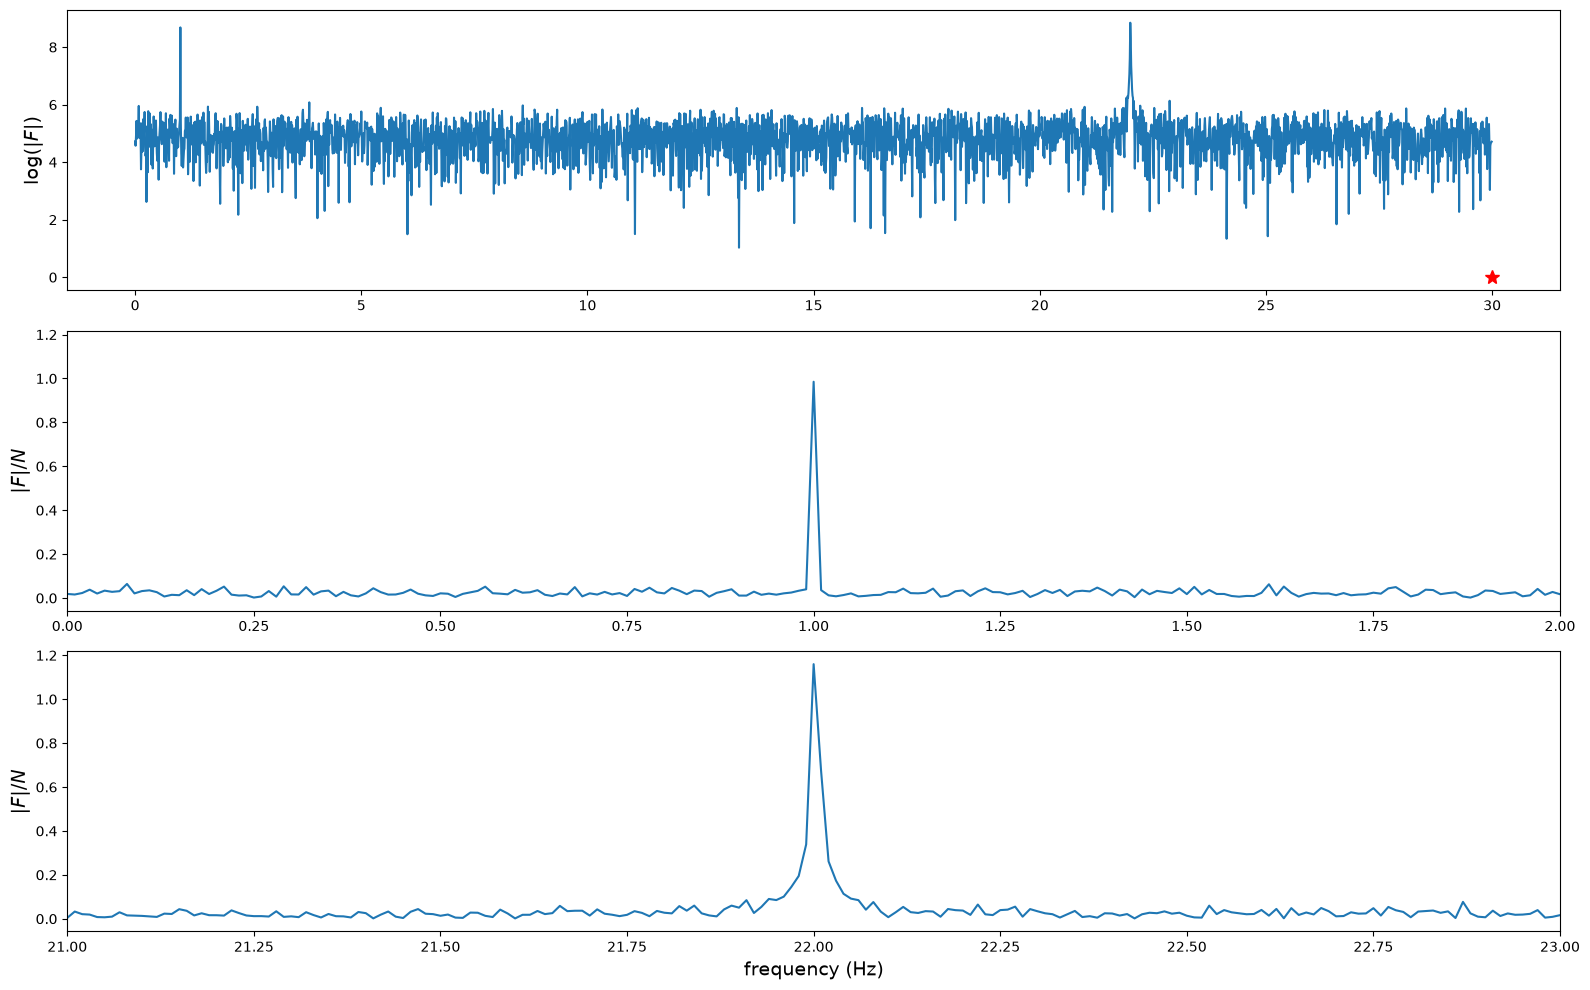

In [16]:
fig, axes = plt.subplots(3, 1, figsize=(16, 10))
axes[0].plot(f[mask], np.log(abs(F[mask])), label="real")
axes[0].plot(B, 0, 'r*', markersize=10)
axes[0].set_ylabel(r"$\log(|F|)$", fontsize=14)
axes[1].plot(f[mask], abs(F[mask])/N, label="real")
axes[1].set_xlim(0, 2)
axes[1].set_ylabel("$|F|/N$", fontsize=14)
axes[2].plot(f[mask], abs(F[mask])/N, label="real")
axes[2].set_xlim(21, 23)
axes[2].set_xlabel("frequency (Hz)", fontsize=14)
axes[2].set_ylabel("$|F|/N$", fontsize=14)

plt.tight_layout()

## 2. Filtracja w dziedzinie częstotliwości (Frequency-Domain Filter)

Skoro funkcja `fft` pozwala przejść z dziedziny czasu do dziedziny częstotliwości, to funkcja odwrotna `ifft` (Inverse FFT) pozwala z powrotem zrekonstruować sygnał czasowy na podstawie jego widma.
Daje nam to potężne narzędzie: **możemy zmodyfikować widmo częstotliwościowe przed wykonaniem transformacji odwrotnej**, realizując w ten sposób filtrację sygnału (np. wycinając niechciane pasma częstotliwości lub szum).

### Zastosowanie filtra dolnoprzepustowego i odwrotnej transformacji (IFFT)
W poniższej komórce:
1. Mnożymy widmo `F` przez maskę logiczną `(abs(f) < 2)`. Działa to jak idealny (prostokątny) **filtr dolnoprzepustowy** o częstotliwości odcięcia $2\text{ Hz}$: wszystkie składowe poniżej $2\text{ Hz}$ (w tym nasz sygnał $1\text{ Hz}$) zostają zachowane, a wszystkie wyższe częstotliwości (szum wysokoczęstotliwościowy oraz składowa $22\text{ Hz}$) są zerowane.
2. Za pomocą funkcji `fftpack.ifft(F_filtered)` obliczamy odwrotną transformację Fouriera:
$$x_n = \frac{1}{N} \sum_{k=0}^{N-1} X_k e^{i 2\pi k n / N}$$
Przywraca ona przefiltrowany sygnał z powrotem do dziedziny czasu.

In [17]:
 F_filtered = F * (abs(f) < 2)
 f_t_filtered = fftpack.ifft(F_filtered)

### Porównanie sygnału oryginalnego i przefiltrowanego
Zestawiamy na wykresie pierwsze $10\text{ s}$ oryginalnego, zaszumionego sygnału (kolor niebieski) oraz sygnału po odfiltrowaniu częstotliwości powyżej $2\text{ Hz}$ (czerwona linia, bierzemy część rzeczywistą `.real`, ponieważ `ifft` zwraca typ zespolony z zerową częścią urojoną). 
Szybkie oscylacje ($22\text{ Hz}$) oraz większość szumu zniknęły – otrzymaliśmy gładką falę sinusoidalną o okresie $1\text{ s}$ ($1\text{ Hz}$).

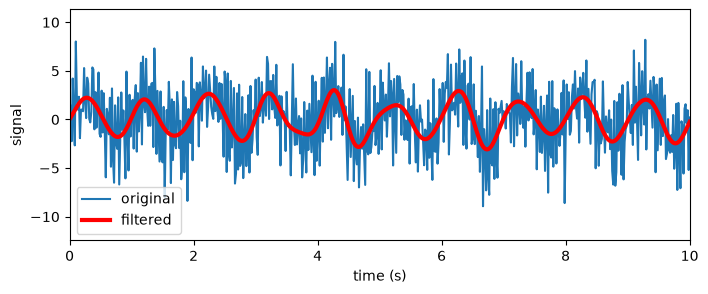

In [18]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(t, f_t, label='original')
ax.plot(t, f_t_filtered.real, color="red", lw=3, label='filtered')
ax.set_xlim(0, 10)
ax.set_xlabel("time (s)")
ax.set_ylabel("signal")
ax.legend()

## 3. Okienkowanie sygnału (Windowing) i przeciek widma

W poprzednim przykładzie zastosowaliśmy FFT bezpośrednio do surowego sygnału. W praktyce często można znacząco poprawić jakość i kontrast widma, mnożąc sygnał przed transformacją przez tzw. **funkcję okna (window function)** – funkcję, która gładko wygasza amplitudę sygnału do zera na początku i na końcu przedziału próbkowania.

### Dlaczego stosujemy okienkowanie? (Teoria w praktyce)
Dyskretna Transformacja Fouriera (DFT) z założenia traktuje analizowany wycinek sygnału tak, jakby był on **nieskończenie powtarzanym sygnałem okresowym**. Jeśli w badanym sygnale występują składowe, których okres nie mieści się całkowitą liczbę razy w czasie pomiaru $T$, to na styku końca jednego okresu pomiarowego i początku „kolejnego” powstaje sztuczna nieciągłość (skok wartości). 
W dziedzinie częstotliwości taki skok objawia się jako tzw. **przeciek widma (spectral leakage)** – energia z właściwej częstotliwości „rozlewa się” na sąsiednie prążki widma, zamazując obraz i utrudniając wykrycie słabszych sygnałów. Przemnożenie sygnału przez funkcję okna łagodzi przejścia na krańcach przedziału i drastycznie redukuje ten problem.

### Porównanie popularnych funkcji okien w `scipy.signal`
Moduł `scipy.signal.windows` (w starszych wersjach bezpośrednio `scipy.signal`) udostępnia wiele gotowych funkcji okien, m.in. **Blackmana, Hanna, Hamminga, Gaussa** (z regulowanym odchyleniem standardowym) oraz **Kaisera**. 
Poniższy wykres pokazuje ich kształt dla próbki o długości $N = 100$. Choć różnią się szczegółami matematycznymi (kompromisem między szerokością piku głównego a tłumieniem listków bocznych), ich ogólny kształt dzwonowy jest bardzo zbliżony i w większości zastosowań można ich używać zamiennie. Okno Blackmana szczególnie dobrze sprawdza się przy redukcji przecieku widma.

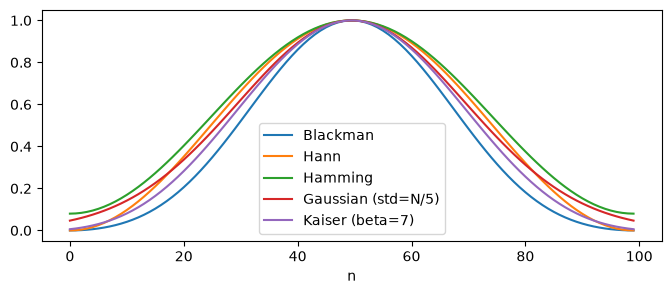

In [19]:
fig, ax = plt.subplots(1, 1, figsize=(8, 3))
N = 100
ax.plot(signal.windows.blackman(N), label="Blackman")
ax.plot(signal.windows.hann(N), label="Hann")
ax.plot(signal.windows.hamming(N), label="Hamming")
ax.plot(signal.windows.gaussian(N, N/5), label="Gaussian (std=N/5)")
ax.plot(signal.windows.kaiser(N, 7), label="Kaiser (beta=7)")
ax.set_xlabel("n")
ax.legend(loc=0)

### Wczytanie i przygotowanie rzeczywistych danych czasowych (temperatura zewnętrzna)
Przechodzimy do przykładu praktycznego na danych rzeczywistych – pomiarach temperatury zewnętrznej w Sztokholmie z 2014 roku. 
Ponieważ algorytm FFT wymaga, aby próbki były rozmieszczone **w równych odstępach czasu**, używamy biblioteki Pandas do uporządkowania szeregu czasowego:
1. Wczytujemy dane z pliku TSV i konwertujemy znaczniki czasu Unix (w sekundach) na datę i godzinę w strefie czasowej `Europe/Stockholm`.
2. Ustawiamy czas jako indeks ramki `DataFrame`.
3. Za pomocą `.resample("h").ffill()` przepróbkowujemy dane do regularnej siatki godzinowej (uzupełniając ewentualne braki ostatnią znaną wartością).
4. Wybieramy dwumiesięczny wycinek od kwietnia do końca maja 2014 r.

In [20]:
df = pd.read_csv('temperature_outdoor_2014.tsv', delimiter="\t", names=["time", "temperature"])
df.time = (pd.to_datetime(df.time.values, unit="s").tz_localize('UTC').tz_convert('Europe/Stockholm'))
df = df.set_index("time")
df = df.resample("h").ffill()
df = df[(df.index >= "2014-04-01") & (df.index < "2014-06-01")].dropna()

### Ekstrakcja tablic NumPy z ramki Pandas
Aby przekazać dane do funkcji z modułu `fftpack`, wyciągamy z obiektu `DataFrame` surowe tablice NumPy: wektor wartości temperatury `temperature` oraz odpowiadający mu wektor czasu `time` wyrażony w sekundach (kolejne godziny przemnożone przez $3600\text{ s}$).

In [21]:
#time = df.index.astype('int64')/1.0e9
#temperature = df.temperature.values

temperature = df["temperature"].values
time = np.arange(len(temperature)) * 3600.0

### Utworzenie okna Blackmana dla szeregu temperatury
Generujemy tablicę z wagami okna Blackmana o długości dokładnie równej liczbie naszych pomiarów temperatury (`len(temperature)`).

In [22]:
 window = signal.windows.blackman(len(temperature))

### Nałożenie okna na sygnał temperatury
Mnożymy oryginalny szereg czasowy `temperature` przez funkcję okna `window`. 
Na wykresie widać, że zokienkowany sygnał (pomarańczowy) zachowuje oscylacje w środkowej części przedziału, ale na brzegach (początek kwietnia i koniec maja) łagodnie dąży do zera. Eliminuje to sztuczny skok wartości między końcem a początkiem okresu pomiarowego, co zapobiegnie rozmyciu widma podczas obliczania FFT.

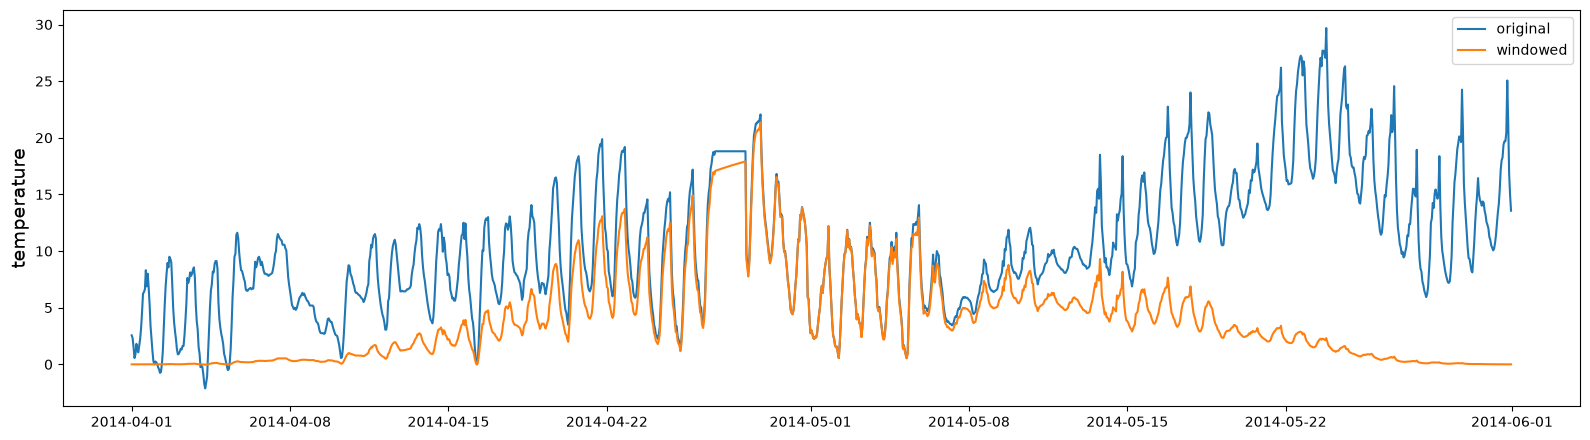

In [24]:
temperature_windowed = temperature * window

fig, ax = plt.subplots(figsize=(16, 4.5))
ax.plot(df.index, temperature, label="original")
ax.plot(df.index, temperature_windowed, label="windowed")
ax.set_ylabel("temperature", fontsize=14)
ax.legend(loc=0)

plt.tight_layout()

### Obliczenie transformacji FFT zokienkowanego sygnału temperatury
Wykonujemy transformację `fftpack.fft` na sygnale przemnożonym przez okno i wyznaczamy odpowiadające jej częstotliwości za pomocą `fftpack.fftfreq` (gdzie krok czasowy `time[1] - time[0]` wynosi $3600\text{ s}$, czyli 1 godzinę).

In [25]:
data_fft_windowed = fftpack.fft(temperature_windowed)
f = fftpack.fftfreq(len(temperature), time[1]-time[0])

### Analiza widma częstotliwościowego temperatury (cykle dobowe i harmoniczne)
Rysujemy dodatnią część widma amplitudowego w skali logarytmicznej. Dodatkowo zaznaczamy pionowymi czerwonymi liniami częstotliwości odpowiadające:
* okresowi **1 doby**: $f_1 = 1 / 86400\text{ Hz} \approx 1.157 \times 10^{-5}\text{ Hz}$ (ponieważ doba ma $24 \times 3600 = 86400\text{ s}$),
* oraz jego wyższym składowym harmonicznym: $2 / 86400\text{ Hz}$ (pół doby) i $3 / 86400\text{ Hz}$ (1/3 doby).

Widmo idealnie pokrywa się z tymi liniami! Główny pik pokazuje silny dobowy cykl nagrzewania i wychładzania powietrza między dniem a nocą.

Text(0.5, 0, 'frequency (Hz)')

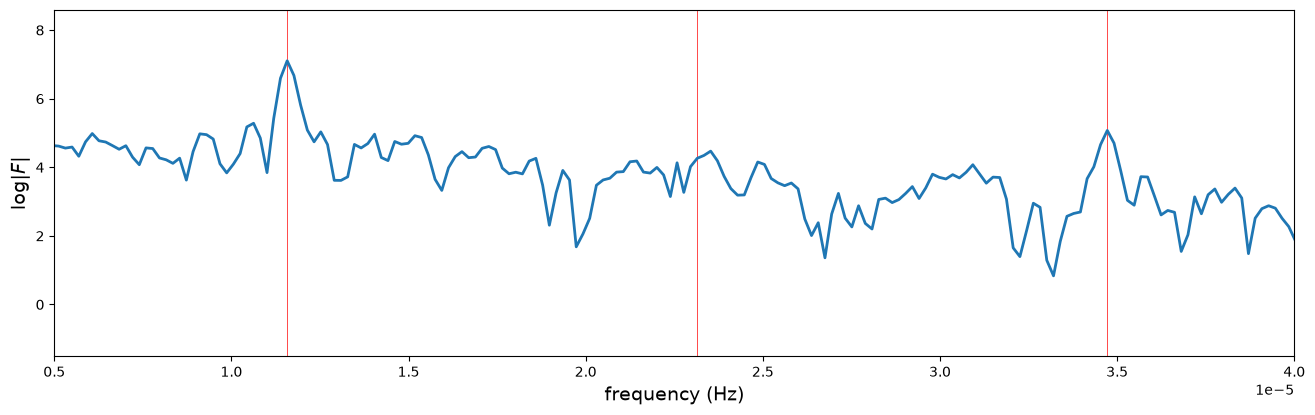

In [28]:
mask = f > 0
fig, ax = plt.subplots(figsize=(16, 4.5))
ax.set_xlim(0.000005, 0.00004)
ax.axvline(1./86400, color='r', lw=0.5)
ax.axvline(2./86400, color='r', lw=0.5)
ax.axvline(3./86400, color='r', lw=0.5)
ax.plot(f[mask], np.log(abs(data_fft_windowed[mask])), lw=2)
ax.set_ylabel("$\\log|F|$", fontsize=14)
ax.set_xlabel("frequency (Hz)", fontsize=14)

## 4. Spektrogram – analiza czasowo-częstotliwościowa (Spectrogram)

W przypadku wielu sygnałów (szczególnie muzyki czy mowy) obliczenie jednego widma FFT dla całego nagrania naraz jest mało użyteczne. Muzyka na krótkich skalach czasowych (ułamków sekund) jest niemal okresowa (brzmi konkretny akord lub nuta), ale na dłuższej skali zmienia się w czasie.

Rozwiązaniem jest obliczanie transformacji FFT w **przesuwnym oknie czasowym** (tzw. *Short-Time Fourier Transform* – STFT). Dzielimy długi sygnał na krótkie, następujące po sobie segmenty i dla każdego z nich osobno liczymy widmo (pamiętając o nałożeniu funkcji okna!). Otrzymujemy w ten sposób **widmo zależne od czasu**, które można przedstawić na dwuwymiarowej mapie ciepła nazywanej **spektrogramem**.

### Wczytanie nagrania audio z pliku WAV
Wczytujemy próbkę dźwięku gitary z pliku `guitar.wav` za pomocą `io.wavfile.read`. Funkcja ta zwraca krotkę składającą się z dwóch elementów:
* `sample_rate` – częstotliwość próbkowania (w Hz),
* `data` – tablica NumPy zawierająca zapisane natężenie dźwięku (amplitudę w kolejnych chwilach czasu).

In [29]:
 sample_rate, data = io.wavfile.read("guitar.wav")

### Sprawdzenie częstotliwości próbkowania
Sprawdzamy wartość `sample_rate`. Wynik $44100\text{ Hz}$ ($44.1\text{ kHz}$) to klasyczny standard jakości CD – oznacza, że w każdej sekundzie nagrania zarejestrowano $44100$ próbek dźwięku.

In [30]:
sample_rate

44100

### Sprawdzenie kształtu tablicy z danymi audio
Właściwość `data.shape` zwraca `(1181625, 2)`. Oznacza to, że nagranie liczy $1\,181\,625$ próbek czasowych i zostało zarejestrowane w **stereo** (posiada 2 kanały audio: lewy i prawy).

In [31]:
data.shape

(1181625, 2)

### Konwersja ze stereo do mono i czas trwania nagrania
Dla uproszczenia analizy widmowej uśredniamy oba kanały wzdłuż drugiej osi (`data.mean(axis=1)`), uzyskując pojedynczy sygnał **mono**. 
Następnie dzielimy całkowitą liczbę próbek przez częstotliwość próbkowania (`data.shape[0] / sample_rate`), co daje łączny czas trwania nagrania wynoszący około $26.8\text{ s}$.

In [32]:
data = data.mean(axis=1)
data.shape[0] / sample_rate

26.79421768707483

### Ustalenie rozmiaru pojedynczego okna czasowego
Zamiast analizować całe $26.8\text{ s}$ naraz, podzielimy sygnał na krótkie, półsekundowe fragmenty ($\Delta T = 0.5\text{ s}$). 
Obliczamy liczbę próbek przypadających na pół sekundy nagrania: $N = 44100 / 2 = 22050$ próbek.

In [33]:
N = int(sample_rate/2.0) # half a second -> 22050 samples

### Przygotowanie osi czasu, częstotliwości i maski pasma dla jednego segmentu
Dla pojedynczego, półsekundowego wycinka ($N = 22050$ próbek):
1. Wyliczamy tablicę częstotliwości `f` za pomocą `fftfreq`.
2. Tworzymy lokalną oś czasu `t` od $0$ do $0.5\text{ s}$.
3. Definiujemy maskę logiczną `mask` wybierającą tylko dodatnie częstotliwości poniżej $1000\text{ Hz}$ (`(f > 0) * (f < 1000)`), ponieważ w tym paśmie skupia się większość podstawowych tonów gitary.

In [34]:
f = fftpack.fftfreq(N, 1.0/sample_rate)
t = np.linspace(0, 0.5, N)
mask = (f > 0) * (f < 1000)

### Obliczenie FFT dla pierwszego półsekundowego fragmentu
Pobieramy pierwsze $N$ próbek nagrania (`subdata = data[:N]`) i wyznaczamy dla nich transformatę Fouriera `F`.

In [35]:
subdata = data[:N]
F = fftpack.fft(subdata)

### Wizualizacja pierwszego fragmentu w dziedzinie czasu i częstotliwości
Zestawiamy przebieg czasowy pierwszych $0.5\text{ s}$ dźwięku gitary (po lewej – widać moment ciszy przed szarpnięciem struny) oraz odpowiadające mu widmo amplitudowe $|F|$ w zakresie do $1000\text{ Hz}$ (po prawej). Wyraźne piki w widmie odpowiadają konkretnym dźwiękom (częstotliwościom podstawowym i harmonicznym) wydobytym z instrumentu.

Text(0.5, 0, 'Frequency (Hz)')

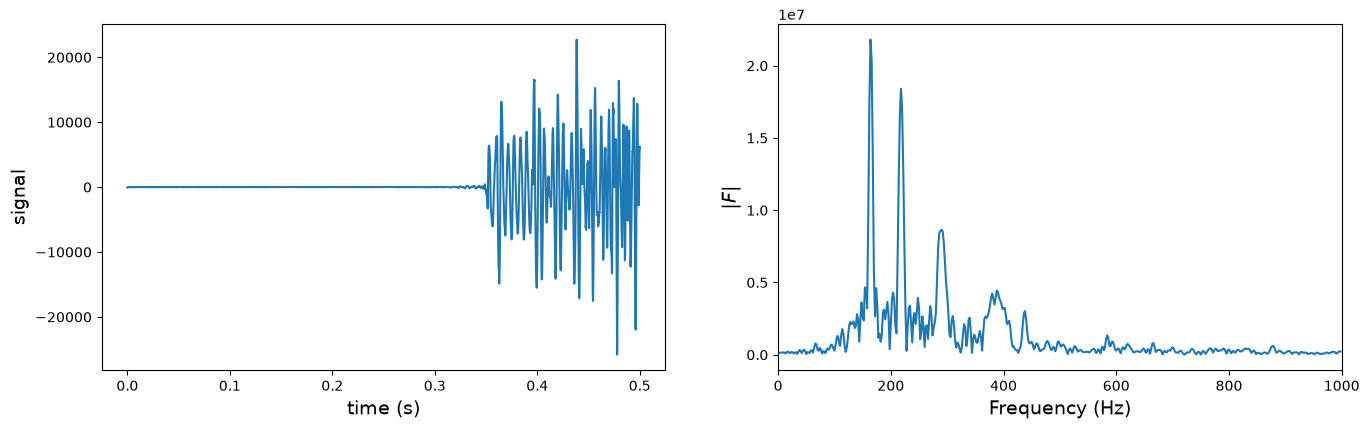

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].plot(t, subdata)
axes[0].set_ylabel("signal", fontsize=14)
axes[0].set_xlabel("time (s)", fontsize=14)
axes[1].plot(f[mask], abs(F[mask]))
axes[1].set_xlim(0, 1000)
axes[1].set_ylabel("$|F|$", fontsize=14)
axes[1].set_xlabel("Frequency (Hz)", fontsize=14)

### Przygotowanie macierzy pod pełny spektrogram
Teraz chcemy powtórzyć powyższą analizę dla wszystkich kolejnych półsekundowych segmentów nagrania:
* `n_max` to całkowita liczba pełnych półsekundowych odcinków mieszczących się w nagraniu ($26.8\text{ s} / 0.5\text{ s} = 53$ segmenty).
* `f_values` to liczba punktów częstotliwości spełniających warunek maski ($0 < f < 1000\text{ Hz}$).
* Inicjalizujemy dwuwymiarową tablicę zer `spectogram_data` o wymiarach `(n_max, f_values)`, w której każdy wiersz będzie reprezentował widmo kolejnego odcinka czasu.

In [39]:
n_max = int(data.shape[0] / N)
f_values = np.sum(mask)
spectogram_data = np.zeros((n_max, f_values))

### Zastosowanie okna Blackmana dla wycinków audio
Aby zredukować przeciek widma na granicach naszych półsekundowych wycinków i poprawić kontrast spektrogramu, przygotowujemy okno Blackmana o długości równej jednemu segmentowi `subdata` ($22050$ próbek).

In [40]:
window = signal.windows.blackman(len(subdata))

### Obliczenie widma w pętli po kolejnych oknach czasowych (STFT)
W pętli przechodzimy przez wszystkie `n_max` segmentów nagrania:
1. Wycinamy kolejny fragment o długości $N$ próbek.
2. Mnożymy go przez okno Blackmana (`subdata * window`).
3. Obliczamy transformatę `fft`.
4. Zapisujemy logarytm modułu widma `np.log(abs(F[mask]))` w odpowiednim wierszu macierzy `spectogram_data`.

In [41]:
for n in range(0, n_max):   
    subdata = data[(N * n):(N * (n + 1))]
    F = fftpack.fft(subdata * window)
    spectogram_data[n, :] = np.log(abs(F[mask]))

### Wyświetlenie spektrogramu jako mapy ciepła (Heatmap)
Wizualizujemy macierz `spectogram_data` za pomocą funkcji `ax.imshow`:
* Oś pozioma przedstawia częstotliwość ($0 - 1000\text{ Hz}$), a oś pionowa czas trwania nagrania ($0 - 26.8\text{ s}$). Parametr `origin='lower'` sprawia, że czas płynie od dołu do góry.
* **Interpretacja wykresu:** Wąskie, pionowe pasma o wysokich wartościach (czerwone/ciemne smugi) to poszczególne tony strun gitary, które stopniowo wygasają w miarę upływu czasu. Z kolei szerokie, poziome prążki pojawiające się w niektórych momentach odpowiadają chwilom szarpnięcia strun – gwałtowny atak generuje krótkotrwały impuls o bardzo szerokim widmie częstotliwości.

<>:5: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:5: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
C:\Users\annag\AppData\Local\Temp\ipykernel_6892\1013809800.py:5: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
  cb.set_label("$\log|F|$", fontsize=14)


Text(0.5, 0, 'Frequency (Hz)')

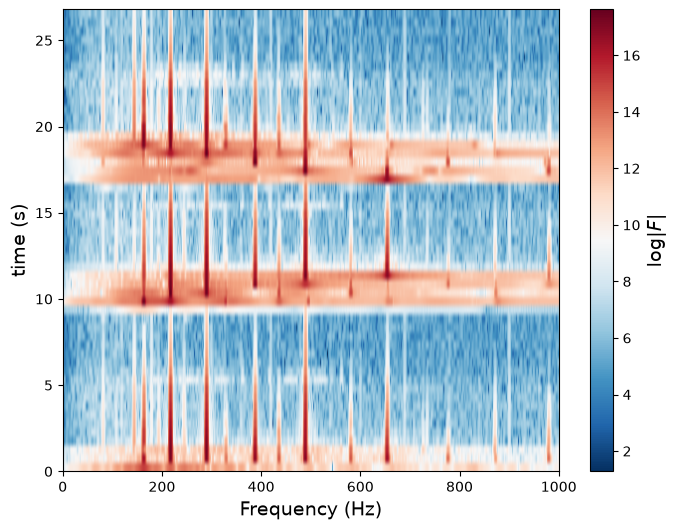

In [42]:
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
p = ax.imshow(spectogram_data, origin='lower',              
extent=(0, 1000, 0, data.shape[0] / sample_rate), aspect='auto', cmap=mpl.cm.RdBu_r)
cb = fig.colorbar(p, ax=ax)
cb.set_label("$\log|F|$", fontsize=14)
ax.set_ylabel("time (s)", fontsize=14)
ax.set_xlabel("Frequency (Hz)", fontsize=14)

## 5. Filtry sygnałowe (Signal Filters)

Jednym z głównych celów przetwarzania sygnałów jest modyfikowanie ich charakterystyk – np. redukcja szumu, nakładanie efektów dźwiękowych w audio czy wyostrzanie/rozmywanie obrazów. 
Poznaliśmy już filtrację w dziedzinie częstotliwości (FFT $\rightarrow$ wycięcie pasma $\rightarrow$ IFFT). Ma ona jednak istotną wadę praktyczną: wymaga zbuforowania całego sygnału (lub dużych jego bloków), przez co trudno ją stosować w czasie rzeczywistym na strumieniu danych (np. podczas rozmowy na żywo). W takich zastosowaniach znacznie lepiej sprawdzają się filtry działające bezpośrednio w dziedzinie czasu.

*(Notatka własna z oryginału: Signal Filters - brak kodu w książce ale może jako zqadanie np dać noise reduction? obczaje to czy to bardzo trudne bo wydaje się bardzo ciekawe)*

### Filtry splotowe (Convolution Filters)

Z twierdzenia o splocie wynika fundamentalna własność transformacji Fouriera: **odwrotna transformacja Fouriera iloczynu dwóch funkcji w dziedzinie częstotliwości jest równa splotowi (konwolucji) ich odwrotnych transformat w dziedzinie czasu**.

Oznacza to, że zamiast mnożyć widmo sygnału $X_k$ przez charakterystykę filtra $H_k$, możemy obliczyć odwrotną transformatę samego filtra $h_m = \mathcal{F}^{-1}(H_k)$ (nazywaną **jądrem splotu** lub odpowiedzią impulsową) i wykonać splot dyskretny bezpośrednio w dziedzinie czasu:
$$y_n = \sum_{k=-\infty}^{\infty} x_k h_{n-k}$$
gdzie $x_k$ to sygnał wejściowy, a $y_n$ to przefiltrowany sygnał wyjściowy.

### Implementacja filtra splotowego i porównanie z filtracją w dziedzinie częstotliwości
Wracamy do naszego pierwszego symulowanego sygnału z częstotliwościami $1\text{ Hz}$ i $22\text{ Hz}$. Chcemy pokazać, że oba podejścia (filtracja widmowa i splot w dziedzinie czasu) dają **identyczny wynik**:
1. Najpierw ponownie generujemy sygnał `f_t` i filtrujemy go w dziedzinie częstotliwości (`f_t_filtered`), odcinając wszystko powyżej $2\text{ Hz}$.
2. Następnie definiujemy funkcję kształtu filtra `H = abs(f) < 2` (prostokątne okno w dziedzinie częstotliwości).
3. Obliczamy jej odwrotną transformatę Fouriera `ifft(H)` i używamy `fftpack.fftshift`, aby wyśrodkować odpowiedź impulsową – otrzymujemy w ten sposób **jądro splotu `h`** (w dziedzinie czasu ma ono postać funkcji $\text{sinc}$).
4. Wykonujemy splot oryginalnego sygnału `f_t` z jądrem `h` za pomocą `signal.convolve(f_t, h, mode='same')`. Argument `mode='same'` gwarantuje, że wynikowa tablica ma dokładnie taką samą długość jak sygnał wejściowy.

In [112]:
t = np.linspace(0, T, N)
f_t = signal_samples(t)

f = fftpack.fftfreq(N, t[1] - t[0])
F = fftpack.fft(f_t)
f_t_filtered = fftpack.ifft(F * (abs(f) < 2))

H = abs(f) < 2
h = fftpack.fftshift(fftpack.ifft(H))
f_t_filtered_conv = signal.convolve(f_t, h, mode='same')

### Wizualizacja filtra częstotliwościowego, jądra splotu i wyników filtracji
Tworzymy zestawienie trzech wykresów (odpowiednik Rysunku 17-9 z książki):
* **Lewy górny:** charakterystyka filtra `H` w dziedzinie częstotliwości (przepuszcza pasmo $[-2, 2]\text{ Hz}$).
* **Prawy górny:** odpowiadające mu jądro splotu `h` w dziedzinie czasu (odpowiedź impulsowa po wyśrodkowaniu).
* **Dolny panel:** nałożone na siebie przebiegi czasowe: sygnał przefiltrowany w dziedzinie częstotliwości (czerwona linia ciągła) oraz sygnał przefiltrowany splotem w dziedzinie czasu (niebieska linia przerywana). Obie krzywe idealnie się pokrywają!

*(Uwaga techniczna: poniższa komórka zawiera sklejony z książki tekst z promptami IPythona `In [63]:` oraz `...:`, ale zgodnie z prośbą pozostawiam kod w komórce bez zmian).*

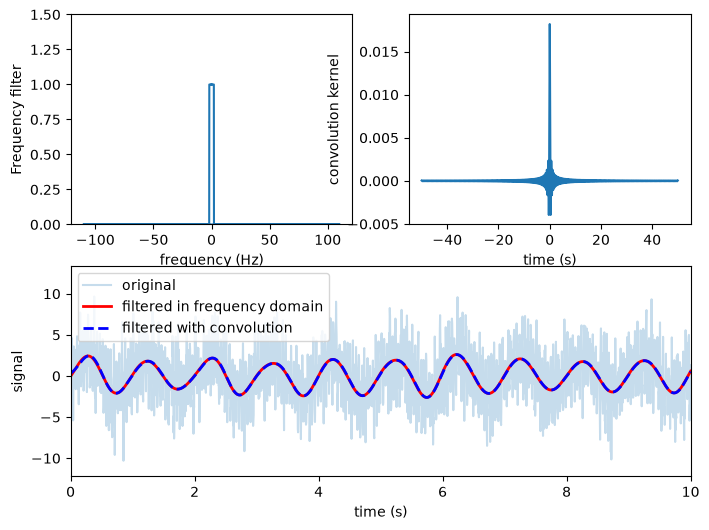

In [113]:
In [63]: fig = plt.figure(figsize=(8, 6))
...: ax = plt.subplot2grid((2,2), (0,0))
...: ax.plot(f, H)
...: ax.set_xlabel("frequency (Hz)")
...: ax.set_ylabel("Frequency filter")
...: ax.set_ylim(0, 1.5)
...: ax = plt.subplot2grid((2,2), (0,1))
...: ax.plot(t - t[-1]/2.0, h.real)
...: ax.set_xlabel("time (s)")
...: ax.set_ylabel("convolution kernel")
...: ax = plt.subplot2grid((2,2), (1,0), colspan=2)
...: ax.plot(t, f_t, label='original', alpha=0.25)
...: ax.plot(t, f_t_filtered.real, 'r', lw=2, label='filtered in frequency domain')
...: ax.plot(t, f_t_filtered_conv.real, 'b--', lw=2, label='filtered with convolution')
...: ax.set_xlim(0, 10)
...: ax.set_xlabel("time (s)")
...: ax.set_ylabel("signal")
...: ax.legend(loc=2)

## 6. Filtry cyfrowe FIR oraz IIR (FIR and IIR Filters)

Ogólny filtr splotowy z poprzedniego przykładu ma pewną wadę: jego jądro $h$ rozciąga się w obie strony osi czasu, co oznacza, że wartość wyjściowa $y_n$ w chwili $n$ zależy również od **przyszłych** wartości sygnału wejściowego $x_k$. Taki filtr nazywamy **nieprzyczynowym (non-causal)** – nie da się go zrealizować w czasie rzeczywistym bez opóźnienia i buforowania przyszłości.

W praktyce inżynierskiej (np. w procesorach sygnałowych DSP) stosuje się dwie szczególne klasy filtrów liniowych, które można obliczać sekwencyjnie krok po kroku:

1. **Filtry FIR (Finite Impulse Response – o skończonej odpowiedzi impulsowej):**
   $$y_n = \sum_{k=0}^{M} b_k x_{n-k}$$
   Wyjście $y_n$ zależy wyłącznie od bieżącej próbki oraz skończonej liczby $M$ **przeszłych** próbek wejścia $x_{n-k}$. Filtr ten jest zawsze przyczynowy i bezwarunkowo stabilny.

2. **Filtry IIR (Infinite Impulse Response – o nieskończonej odpowiedzi impulsowej):**
   $$a_0 y_n = \sum_{k=0}^{M} b_k x_{n-k} - \sum_{k=1}^{N} a_k y_{n-k}$$
   Oprócz przeszłych próbek wejścia wykorzystują one także **przeszłe wartości wyjścia $y_{n-k}$** (człon sprzężenia zwrotnego / rekurencji). Pozwala to uzyskać bardzo ostre charakterystyki filtracji przy znacznie mniejszej liczbie współczynników niż w filtrach FIR.

### Projektowanie dolnoprzepustowego filtra FIR (`signal.firwin`)
Wyznaczanie współczynników $b_k$ oraz $a_k$ dla zadanych parametrów nazywamy **projektowaniem filtra (filter design)**. 
Poniżej projektujemy dolnoprzepustowy filtr FIR dla naszych danych o temperaturze zewnętrznej (próbkowanych co godzinę, czyli $f_s = 1/3600\text{ Hz}$):
* Ustalamy długość filtra na `n = 101` współczynników (tzw. *taps*).
* Obliczamy częstotliwość Nyquista `nyq = f_s / 2` (co odpowiada okresowi 2 godzin).
* Za pomocą funkcji `signal.firwin` wyznaczamy współczynniki `b` filtra dolnoprzepustowego z częstotliwością odcięcia `cutoff = nyq / 12` (czyli $f_s / 24$, co odpowiada okresowi **24 godzin / 1 doby**) i oknem Hamminga. Taki filtr ma przepuszczać powolne zmiany wielodniowe, a tłumić wahania szybsze niż dobowe.

In [116]:
n = 101
f_s = 1 / 3600
nyq = f_s/2
b = signal.firwin(n, cutoff=nyq/12, fs=f_s, window="hamming")

### Charakterystyka amplitudowa i fazowa filtra FIR (`signal.freqz`)
Mając współczynniki `b`, używamy funkcji `signal.freqz(b)`, aby obliczyć zespoloną odpowiedź częstotliwościową filtra `h` dla zadanych częstotliwości `f`:
* **Wykres niebieski (oś lewa):** wzmocnienie (odpowiedź amplitudowa) wyrażone w decybelach: $20 \log_{10}|h|$. Widać, że powyżej częstotliwości odcięcia (zaznaczonej pionową czarną linią na $1/12$ częstotliwości Nyquista) sygnał jest silnie tłumiony.
* **Wykres czerwony (oś prawa):** odpowiedź fazowa (po rozwinięciu skoków fazy za pomocą `np.unwrap(np.angle(h))`).

Zauważmy, że przejście między pasmem przepustowym a zaporowym nie jest pionowym schodkiem (jak w idealnym filtrze FFT), lecz ma skończone nachylenie i drobne zafalowania – to cena, jaką płacimy za skończoną liczbę współczynników $b_k$ i przyczynowość filtra. Dokładność można zwiększyć, zwiększając `n`, ale kosztem większego narzutu obliczeniowego.

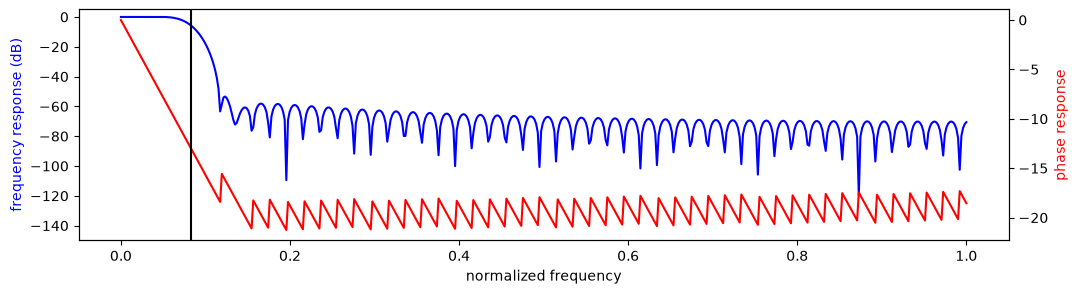

In [117]:
f, h = signal.freqz(b)
fig, ax = plt.subplots(1, 1, figsize=(12, 3))
h_ampl = 20 * np.log10(abs(h))
h_phase = np.unwrap(np.angle(h))
ax.plot(f/max(f), h_ampl, 'b')
ax.set_ylim(-150, 5)
ax.set_ylabel('frequency response (dB)', color="b")
ax.set_xlabel(r'normalized frequency')
ax = ax.twinx()
ax.plot(f/max(f), h_phase, 'r')
ax.set_ylabel('phase response', color="r")
ax.axvline(1.0/12, color="black")

### Aplikacja filtra FIR do szeregu temperatury (`signal.lfilter`)
Funkcja `signal.lfilter(b, a, x)` aplikuje filtr liniowy do sygnału `x`. Dla filtra FIR mianownik transmitancji jest stały i wynosi $a_0 = 1$, dlatego jako drugi argument przekazujemy skalar `1`. 
Wynikiem jest wygładzony przebieg temperatury `temperature_filt`, pozbawiony szybkich, dobowych wahań.

In [118]:
 temperature_filt = signal.lfilter(b, 1, temperature)

### Alternatywne wygładzanie: filtr medianowy (`signal.medfilt`)
Podobny efekt wygładzenia i usunięcia krótkotrwałych wahań można uzyskać za pomocą **filtru ruchomej mediany** (`signal.medfilt`), który dla każdego punktu zwraca medianę z pewnego otoczenia (tutaj z okna o szerokości `25` sąsiednich godzin).

In [119]:
temperature_median_filt = signal.medfilt(temperature, 25)

### Porównanie filtra FIR oraz filtra medianowego na wykresie
Zestawiamy oryginalny przebieg temperatury (półprzezroczysty niebieski), wynik działania filtra FIR (czerwony) oraz filtra medianowego (zielony).
* **Ważna obserwacja praktyczna:** Wykres filtra FIR (czerwony) jest **przesunięty w prawo (opóźniony w czasie)** względem oryginału! Wynika to z faktu, że przyczynowy filtr FIR bazuje wyłącznie na próbkach historycznych, co wprowadza tzw. opóźnienie grupowe (odpowiadające połowie liczby współczynników *taps* filtra).
* Filtr medianowy `medfilt` (zielony) nie ma tego przesunięcia, ponieważ liczy medianę symetrycznie z próbek przeszłych i przyszłych – jest więc filtrem **nieprzyczynowym** i nie dałoby się go użyć „w locie” na strumieniu danych czasu rzeczywistego.

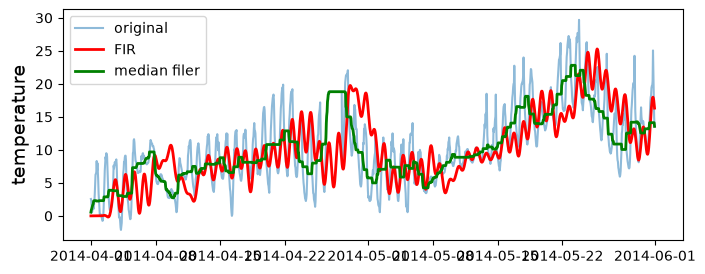

In [120]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(df.index, temperature, label="original", alpha=0.5)
ax.plot(df.index, temperature_filt, color="red", lw=2, label="FIR")
ax.plot(df.index, temperature_median_filt, color="green", lw=2, label="median filer")
ax.set_ylabel("temperature", fontsize=14)
ax.legend(loc=0)

### Projektowanie górnoprzepustowego filtra IIR Butterwortha (`signal.butter`)
Do projektowania filtrów IIR w `scipy.signal` możemy użyć m.in. klasycznych filtrów **Butterwortha** (`butter`), Czebyszewa (`cheby1`, `cheby2`) lub eliptycznych (`ellip`).
Tutaj tworzymy **górnoprzepustowy (`btype='high'`) filtr Butterwortha 2. rzędu** o częstotliwości krytycznej `7 / 365.0` (w znormalizowanych jednostkach częstotliwości Nyquista). Filtr górnoprzepustowy działa odwrotnie niż dolnoprzepustowy: blokuje powolne trendy długoterminowe, a przepuszcza jedynie szybkie fluktuacje i oscylacje.

In [121]:
b, a = signal.butter(2, 7/365.0, btype='high')

### Współczynniki licznika `b` filtra IIR
Ponieważ wybraliśmy filtr 2. rzędu, tablica współczynników $b_k$ (odpowiadających próbkom wejściowym $x$) ma 3 elementy.

In [122]:
b

array([ 0.95829139, -1.91658277,  0.95829139])

### Współczynniki mianownika `a` filtra IIR (sprzężenie zwrotne)
Tablica $a_k$ (odpowiadająca przeszłym próbkom wyjściowym $y$, przy czym $a_0 = 1$) również składa się z 3 elementów.

In [123]:
a

array([ 1.        , -1.91484241,  0.91832314])

### Aplikacja przyczynowego filtra IIR (`signal.lfilter`)
Stosujemy zaprojektowany filtr Butterwortha do szeregu temperatury za pomocą `signal.lfilter(b, a, temperature)` (tym razem przekazując zarówno `b`, jak i `a`).

In [124]:
 temperature_iir = signal.lfilter(b, a, temperature)

### Aplikacja filtra bez przesunięcia fazowego (`signal.filtfilt`)
Alternatywnie stosujemy funkcję `signal.filtfilt(b, a, temperature)`. Aplikuje ona ten sam filtr IIR **dwukrotnie**: najpierw w przód (zgodnie z biegiem czasu), a następnie w tył (od końca do początku danych). 
Dzięki temu przesunięcia fazowe (opóźnienia czasowe) z obu przebiegów wzajemnie się znoszą! Ceną za brak opóźnienia jest to, że `filtfilt` wymaga dostępu do całego sygnału naraz (jest nieprzyczynowy).

In [125]:
 temperature_filtfilt = signal.filtfilt(b, a, temperature)

### Wizualizacja filtracji górnoprzepustowej (usuwanie trendu / detrending)
Wykres pokazuje efekt odcięcia niskich częstotliwości: z szeregu czasowego zniknął długofalowy trend sezonowy (wzrost średniej temperatury od wiosny do lata), a pozostały jedynie szybkie wahania dobowe oscylujące wokół zera. Taki przefiltrowany sygnał świetnie mierzy **zmienność (volatility)** badanego zjawiska.

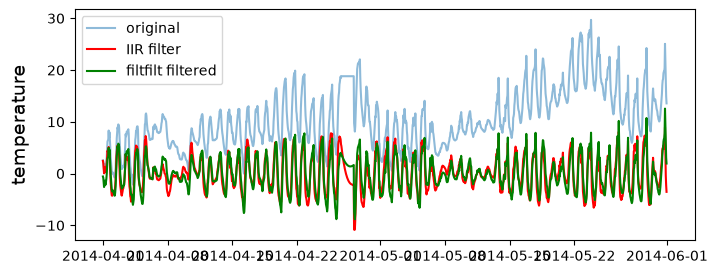

In [126]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(df.index, temperature, label="original", alpha=0.5)
ax.plot(df.index, temperature_iir, color="red", label="IIR filter")
ax.plot(df.index, temperature_filtfilt, color="green", label="filtfilt filtered")
ax.set_ylabel("temperature", fontsize=14)
ax.legend(loc=0)

### Praktyczne zastosowanie na audio: efekt echa za pomocą filtra FIR
Techniki filtracji liniowej można bezpośrednio stosować do przetwarzania dźwięku i obrazu. Współczynniki $b_k$ filtra FIR można też skonstruować ręcznie, kierując się intuicją fizyczną.
Chcemy dodać do naszego nagrania gitary prosty **efekt echa**, czyli powtórzyć dźwięk z pewnym opóźnieniem czasowym $N$:
$$y_n = \frac{1}{2} (x_n + x_{n-N})$$
W kodzie:
1. Tworzymy tablicę zer `b` o długości $N = 10000$ próbek (przy $f_s = 44100\text{ Hz}$ opóźnienie $10000$ próbek odpowiada ok. $0.227\text{ s}$).
2. Ustawiamy pierwszy (`b[0] = 1`, dźwięk bieżący) oraz ostatni element (`b[-1] = 1`, dźwięk sprzed $0.227\text{ s}$) na $1$.
3. Normalizujemy wektor `b /= b.sum()` (aby nie przesterować głośności).
4. Przepuszczamy sygnał gitary przez `signal.lfilter(b, 1, data)`.

In [133]:
b = np.zeros(10000)
b[0] = b[-1] = 1
b /= b.sum()
data_filt = signal.lfilter(b, 1, data, axis=0)

### Zapisanie zmodyfikowanego dźwięku z efektem echa do pliku WAV
Na koniec zapisujemy przefiltrowaną tablicę `data_filt` (po rzutowaniu na 16-bitowe liczby całkowite `np.int16`, standardowe dla formatu PCM WAV) do nowego pliku `guitar-echo.wav` za pomocą `io.wavfile.write`. Po jego odtworzeniu usłyszymy oryginalną gitarę z wyraźnym pogłosem (echem).

In [136]:
#io.wavfile.write("guitar-echo.wav", sample_rate, np.vstack([data_filt, data_filt]).T.astype(np.int16))
io.wavfile.write("guitar-echo.wav", sample_rate, data_filt.astype(np.int16))